# x

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C203ThinF_IMG_20151029_102123_cell_51.png
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C238NThinF_IMG_20151207_114038_cell_84.png
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C119P80ThinF_IMG_20151002_124304_cell_112.png
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C39P4thinF_original_IMG_20150622_111723_cell_33.png
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C101P62ThinF_IMG_20150918_151149_cell_63.png
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C180P141NThinF_IMG_20151201_165601_cell_115.png
/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C95P56ThinF_IMG_20150821_171603_cell_75.png
/kaggle/input/datasets/iarunava/cell-images-for-detecting

In [2]:
# ── Core libraries ─────────────────────────────────────────────────────────────
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

# ── Keras components ───────────────────────────────────────────────────────────
from tensorflow.keras.applications import EfficientNetB2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    BatchNormalization
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)
from tensorflow.keras.optimizers import Adam

print("TensorFlow version :", tf.__version__)
print("GPUs available     :", tf.config.list_physical_devices('GPU'))
print("All imports successful!")

2026-06-18 04:11:20.638434: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781755880.865566      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781755880.944063      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781755881.502301      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781755881.502342      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781755881.502345      23 computation_placer.cc:177] computation placer alr

TensorFlow version : 2.19.0
GPUs available     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
All imports successful!


In [3]:
# ── All hyperparameters in one place ───────────────────────────────────────────
# Changing any value here automatically propagates through every block below

DATA_DIR   = "/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images"
IMG_SIZE   = 128    # 128x128 px -- fits in Kaggle RAM; captures parasite detail
BATCH_SIZE = 32     # Matches Mujahid et al. (2024)
EPOCHS     = 50     # EarlyStopping will cut short if val_accuracy plateaus
SEED       = 42     # Fixed seed -- reproducible splits and shuffles every run

# Class folder paths derived from DATA_DIR
PARASITIZED_DIR = os.path.join(DATA_DIR, "Parasitized")
UNINFECTED_DIR  = os.path.join(DATA_DIR, "Uninfected")

print("Configuration")
print(f"  Data directory : {DATA_DIR}")
print(f"  Image size     : {IMG_SIZE} x {IMG_SIZE} px")
print(f"  Batch size     : {BATCH_SIZE}")
print(f"  Max epochs     : {EPOCHS}")
print(f"  Random seed    : {SEED}")

Configuration
  Data directory : /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/cell_images
  Image size     : 128 x 128 px
  Batch size     : 32
  Max epochs     : 50
  Random seed    : 42


In [4]:
def load_folder(folder_path, label, img_size):
    """
    Read every valid image in folder_path, resize to img_size x img_size,
    and assign the given integer label.
    Pixel values kept in 0-255 range -- EfficientNetB2 has its own internal
    preprocessing layer that handles normalisation. Dividing by 255 here
    causes double-normalisation and breaks training entirely.
    """
    images, labels = [], []
    valid_ext = ('.png', '.jpg', '.jpeg')
    files = [f for f in os.listdir(folder_path) if f.lower().endswith(valid_ext)]
    print(f"  Loading {len(files):,} images from '{os.path.basename(folder_path)}'...")

    for fname in files:
        fpath = os.path.join(folder_path, fname)
        try:
            img = tf.keras.utils.load_img(fpath, target_size=(img_size, img_size))
            # img_to_array gives float32 in range 0-255
            # Do NOT divide by 255 -- EfficientNetB2 rescales internally
            arr = tf.keras.utils.img_to_array(img)
            images.append(arr)
            labels.append(label)
        except Exception:
            pass

    return images, labels

print("Loading dataset...")
para_imgs,  para_lbls  = load_folder(PARASITIZED_DIR, label=0, img_size=IMG_SIZE)
uninf_imgs, uninf_lbls = load_folder(UNINFECTED_DIR,  label=1, img_size=IMG_SIZE)

X = np.array(para_imgs + uninf_imgs, dtype=np.float32)
y = np.array(para_lbls + uninf_lbls, dtype=np.float32)

print()
print(f"Total images     : {X.shape[0]:,}")
print(f"Image shape      : {X.shape[1:]}  (H x W x channels)")
print(f"Pixel value range: {X.min():.0f} to {X.max():.0f}  (0-255, NOT normalised)")
print(f"Parasitized      : {int(np.sum(y == 0)):,}  (label 0)")
print(f"Uninfected       : {int(np.sum(y == 1)):,}  (label 1)")
print(f"Memory used      : {X.nbytes / 1e9:.2f} GB")

Loading dataset...
  Loading 13,779 images from 'Parasitized'...
  Loading 13,779 images from 'Uninfected'...

Total images     : 27,558
Image shape      : (128, 128, 3)  (H x W x channels)
Pixel value range: 0 to 255  (0-255, NOT normalised)
Parasitized      : 13,779  (label 0)
Uninfected       : 13,779  (label 1)
Memory used      : 5.42 GB


In [5]:
# ── Three-way stratified split ─────────────────────────────────────────────────
# We split into THREE sets -- not two -- so that:
#   Training set  : model learns from this (weights are updated)
#   Validation set: monitored during training for early stopping and checkpoints
#   Test set      : completely unseen until final evaluation -- gives an honest
#                   estimate of real-world performance
#
# stratify=y preserves the 50/50 class balance in every split.
# All splits use SEED so results are reproducible.

# Step 1: carve out 15% as the held-out test set
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size    = 0.15,   # 15% test
    random_state = SEED,
    stratify     = y
)

# Step 2: from the remaining 85%, take ~12% as validation
# 0.12 / 0.85 ≈ 0.118 → gives roughly a 73 / 12 / 15 overall split
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size    = 0.118,
    random_state = SEED,
    stratify     = y_trainval
)

print("Dataset split summary")
print(f"  Training   : {X_train.shape[0]:,} images  "
      f"(Para: {int(np.sum(y_train==0)):,}  Uninf: {int(np.sum(y_train==1)):,})")
print(f"  Validation : {X_val.shape[0]:,}  images  "
      f"(Para: {int(np.sum(y_val==0)):,}   Uninf: {int(np.sum(y_val==1)):,})")
print(f"  Test       : {X_test.shape[0]:,}  images  "
      f"(Para: {int(np.sum(y_test==0)):,}   Uninf: {int(np.sum(y_test==1)):,})")
print()
print("Test set is locked away -- not used until the final evaluation block.")

Dataset split summary
  Training   : 20,659 images  (Para: 10,329  Uninf: 10,330)
  Validation : 2,765  images  (Para: 1,383   Uninf: 1,382)
  Test       : 4,134  images  (Para: 2,067   Uninf: 2,067)

Test set is locked away -- not used until the final evaluation block.


In [6]:
# ── Augmentation function (training images only) ───────────────────────────────
# Images are now in 0-255 range to match EfficientNetB2's expected input.
# Augmentation still applies the same transformations but clips to 0-255.

def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, 0.15)
    image = tf.image.random_contrast(image, 0.85, 1.15)
    # Clip to valid pixel range for 0-255 input
    image = tf.clip_by_value(image, 0.0, 255.0)
    return image, label

# ── Training pipeline ──────────────────────────────────────────────────────────
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED)
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# ── Validation pipeline (no augmentation) ─────────────────────────────────────
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("tf.data pipelines built")
print(f"  Training batches   : {len(train_ds)}")
print(f"  Validation batches : {len(val_ds)}")
print("  Pixel range        : 0-255  (EfficientNetB2 preprocesses internally)")

I0000 00:00:1781756011.144459      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781756011.150387      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


tf.data pipelines built
  Training batches   : 646
  Validation batches : 87
  Pixel range        : 0-255  (EfficientNetB2 preprocesses internally)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..224.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..223.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..216.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..228.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..217.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..252.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..215.0].
Clipping input data to the valid range for imshow with RGB dat

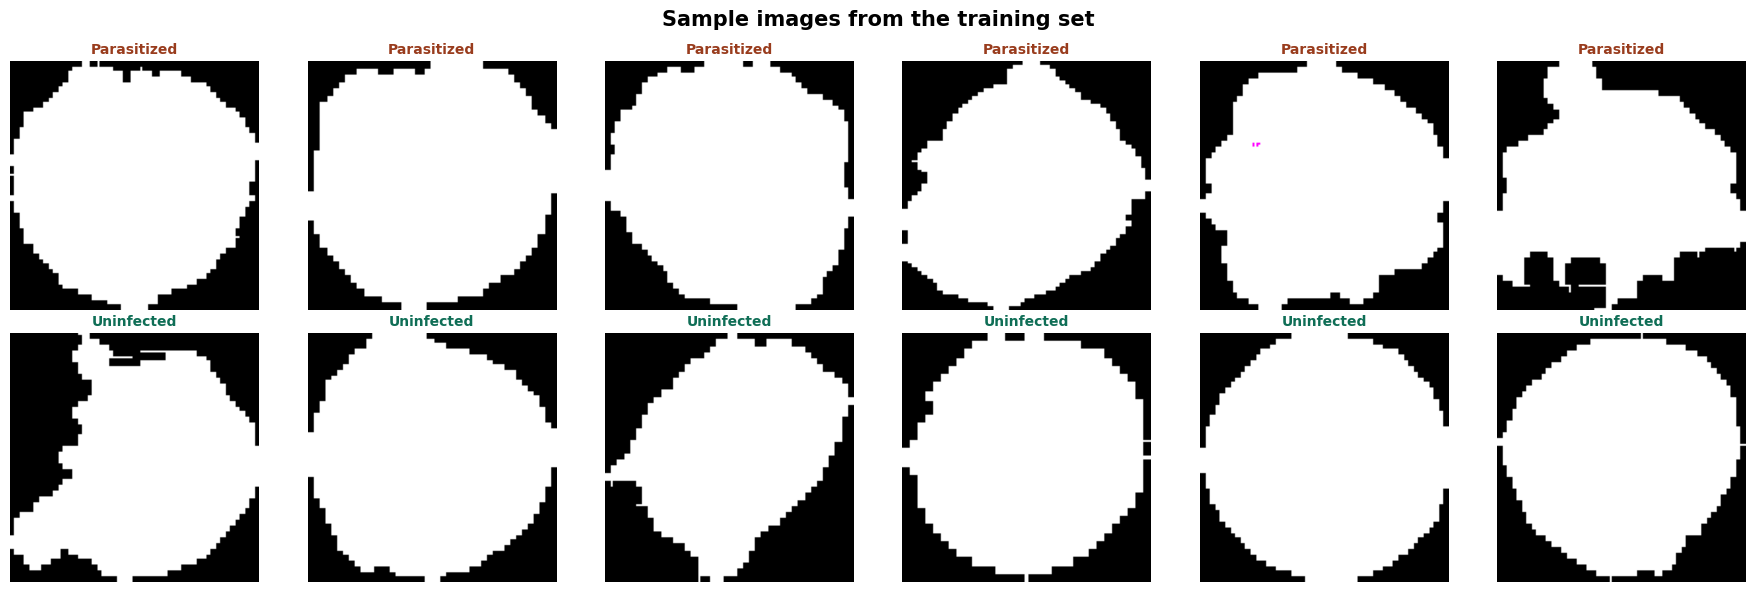

Visualisation complete.


In [7]:
# ── Display a sample grid before training ──────────────────────────────────────
# Always visually inspect your data before training -- confirms loading is correct
# and gives you a feel for the visual challenge the model faces.

fig, axes = plt.subplots(2, 6, figsize=(18, 6))
fig.suptitle("Sample images from the training set", fontsize=15, fontweight='bold')

para_idx  = np.where(y_train == 0)[0]
uninf_idx = np.where(y_train == 1)[0]

for i in range(6):
    # Top row: parasitized cells -- look for dark purple spots/rings inside
    idx = np.random.choice(para_idx)
    axes[0, i].imshow(X_train[idx])
    axes[0, i].set_title("Parasitized", color='#993C1D', fontsize=10, fontweight='bold')
    axes[0, i].axis('off')

    # Bottom row: uninfected cells -- clean, uniform pink/red circles
    idx = np.random.choice(uninf_idx)
    axes[1, i].imshow(X_train[idx])
    axes[1, i].set_title("Uninfected", color='#0F6E56', fontsize=10, fontweight='bold')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()
print("Visualisation complete.")

In [8]:
# ── Load EfficientNetB2 ────────────────────────────────────────────────────────
# In TensorFlow 2.x Keras, EfficientNetB2 includes internal preprocessing
# automatically -- no extra parameter needed.
# It expects pixel values in 0-255 range and handles rescaling itself.
# This is why we removed the /255.0 in Block 3.
base_model = EfficientNetB2(
    weights     = 'imagenet',
    include_top = False,
    input_shape = (IMG_SIZE, IMG_SIZE, 3)
)

# ── Freeze all layers first ────────────────────────────────────────────────────
base_model.trainable = False

# Unfreeze top 20 layers only, keeping all BatchNorm layers frozen.
# BatchNorm layers must stay frozen -- unfreezing them shifts the running
# mean/variance and destabilises training.
for layer in base_model.layers[-20:]:
    if not isinstance(layer, BatchNormalization):
        layer.trainable = True

frozen_count   = sum(1 for l in base_model.layers if not l.trainable)
unfrozen_count = sum(1 for l in base_model.layers if l.trainable)
print(f"EfficientNetB2 loaded")
print(f"  Total base layers    : {len(base_model.layers)}")
print(f"  Frozen layers        : {frozen_count}")
print(f"  Unfrozen layers      : {unfrozen_count}")

# ── Verify the internal preprocessing is present ──────────────────────────────
# The first layer of EfficientNetB2 should be a Rescaling layer.
# If you see 'rescaling' in the output below, preprocessing is built in.
print(f"  First layer name     : {base_model.layers[0].name}")
print(f"  Second layer name    : {base_model.layers[1].name}")

# ── Classification head ────────────────────────────────────────────────────────
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.1)(x)

# Single sigmoid output: 0 = Parasitized, 1 = Uninfected
predictions = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=predictions)

# ── Compile ────────────────────────────────────────────────────────────────────
model.compile(
    optimizer = Adam(learning_rate=1e-3),
    loss      = 'binary_crossentropy',
    metrics   = ['accuracy']
)

total_params     = model.count_params()
trainable_params = sum([tf.size(w).numpy() for w in model.trainable_weights])
print()
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Frozen parameters    : {total_params - trainable_params:,}")
print()
print("Model compiled and ready!")

31790344/31790344 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetB2 loaded
  Total base layers    : 340
  Frozen layers        : 325
  Unfrozen layers      : 15
  First layer name     : input_layer
  Second layer name    : rescaling

Total parameters     : 8,136,186
Trainable parameters : 3,178,969
Frozen parameters    : 4,957,217

Model compiled and ready!


In [9]:
# ── Callbacks ─────────────────────────────────────────────────────────────────

# Saves model weights whenever val_accuracy improves during training.
# best_malasense_model.keras always holds the best version found so far.
checkpoint = ModelCheckpoint(
    filepath       = 'best_malasense_model.keras',
    monitor        = 'val_accuracy',
    save_best_only = True,
    mode           = 'max',
    verbose        = 1
)

# Stops training automatically if val_accuracy does not improve for 7 epochs.
# restore_best_weights=True reloads the best checkpoint when stopping,
# so the model object holds the best weights even after early stopping.
early_stopping = EarlyStopping(
    monitor              = 'val_accuracy',
    patience             = 7,
    mode                 = 'max',
    verbose              = 1,
    restore_best_weights = True
)

# If val_loss does not improve for 3 epochs, cuts learning rate by 70%.
# Helps the optimiser settle into a better minimum when it gets stuck.
reduce_lr = ReduceLROnPlateau(
    monitor  = 'val_loss',
    factor   = 0.3,
    patience = 3,
    min_lr   = 1e-7,
    verbose  = 1
)

print("Callbacks configured")
print("  ModelCheckpoint   : saves best model to 'best_malasense_model.keras'")
print("  EarlyStopping     : stops if no improvement for 7 epochs")
print("  ReduceLROnPlateau : reduces LR by 0.3x if stuck for 3 epochs")
print()
print("Starting training...")
print("=" * 60)

history = model.fit(
    train_ds,
    epochs          = EPOCHS,
    validation_data = val_ds,
    callbacks       = [checkpoint, early_stopping, reduce_lr],
    verbose         = 1
)

print()
print("=" * 60)
print("Training complete!")
print(f"  Epochs completed         : {len(history.history['accuracy'])}")
print(f"  Best validation accuracy : {max(history.history['val_accuracy'])*100:.2f}%")

Callbacks configured
  ModelCheckpoint   : saves best model to 'best_malasense_model.keras'
  EarlyStopping     : stops if no improvement for 7 epochs
  ReduceLROnPlateau : reduces LR by 0.3x if stuck for 3 epochs

Starting training...
Epoch 1/50


I0000 00:00:1781756045.990006      71 service.cc:152] XLA service 0x7bbc48002380 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781756045.991162      71 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1781756045.991176      71 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1781756049.634516      71 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-18 04:14:18.766751: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:14:18.901669: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:14:19.220485: E external/local_xl

644/646 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9072 - loss: 0.2568

2026-06-18 04:14:59.147279: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:14:59.281652: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:14:59.598651: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:14:59.743565: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:15:00.594352: E external/local_xla/xla/stream_

646/646 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.9073 - loss: 0.2567

2026-06-18 04:15:30.763535: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:15:30.897665: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:15:31.216891: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:15:31.361970: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:15:32.177411: E external/local_xla/xla/stream_


Epoch 1: val_accuracy improved from None to 0.94647, saving model to best_malasense_model.keras

Epoch 1: finished saving model to best_malasense_model.keras
646/646 ━━━━━━━━━━━━━━━━━━━━ 112s 100ms/step - accuracy: 0.9222 - loss: 0.2103 - val_accuracy: 0.9465 - val_loss: 0.1379 - learning_rate: 0.0010
Epoch 2/50
644/646 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9379 - loss: 0.1690
Epoch 2: val_accuracy improved from 0.94647 to 0.96022, saving model to best_malasense_model.keras

Epoch 2: finished saving model to best_malasense_model.keras
646/646 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.9398 - loss: 0.1641 - val_accuracy: 0.9602 - val_loss: 0.1165 - learning_rate: 0.0010
Epoch 3/50
646/646 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9424 - loss: 0.1559
Epoch 3: val_accuracy improved from 0.96022 to 0.96347, saving model to best_malasense_model.keras

Epoch 3: finished saving model to best_malasense_model.keras
646/646 ━━━━━━━━━━━━━━━━━━━━ 18s 29ms/step - accuracy: 0.

Running predictions on validation and test sets...
87/87 ━━━━━━━━━━━━━━━━━━━━ 19s 123ms/step
128/130 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

2026-06-18 04:19:27.476175: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:19:27.610589: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:19:27.916200: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:19:28.061155: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-18 04:19:28.205145: E external/local_xla/xla/stream_

130/130 ━━━━━━━━━━━━━━━━━━━━ 16s 121ms/step
Validation -- unique prediction counts : (array([0, 1]), array([1385, 1380]))
Test       -- unique prediction counts : (array([0, 1]), array([2053, 2081]))

VALIDATION SET -- Classification Report
              precision    recall  f1-score   support

 Parasitized       0.97      0.97      0.97      1383
  Uninfected       0.97      0.97      0.97      1382

    accuracy                           0.97      2765
   macro avg       0.97      0.97      0.97      2765
weighted avg       0.97      0.97      0.97      2765

TEST SET -- Classification Report
              precision    recall  f1-score   support

 Parasitized       0.96      0.95      0.96      2067
  Uninfected       0.95      0.96      0.96      2067

    accuracy                           0.96      4134
   macro avg       0.96      0.96      0.96      4134
weighted avg       0.96      0.96      0.96      4134

VALIDATION -- Clinical Performance Metrics
----------------------------

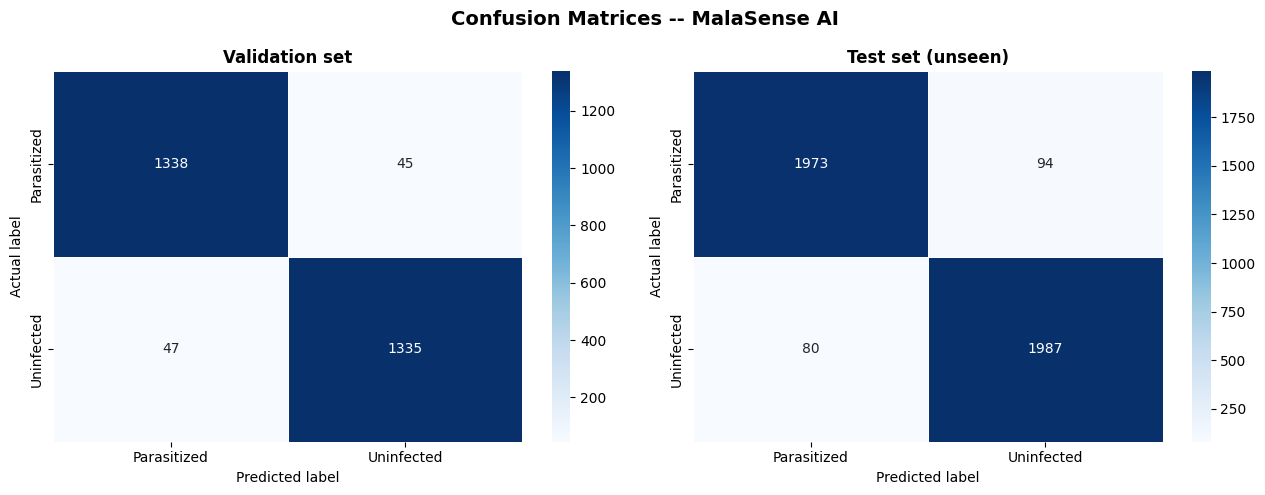

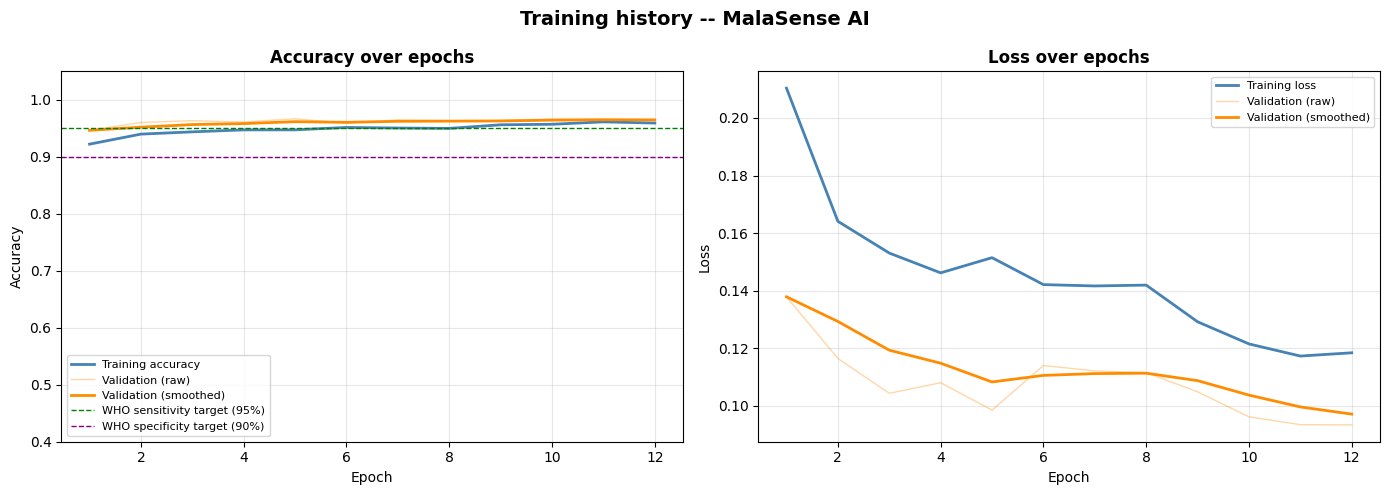

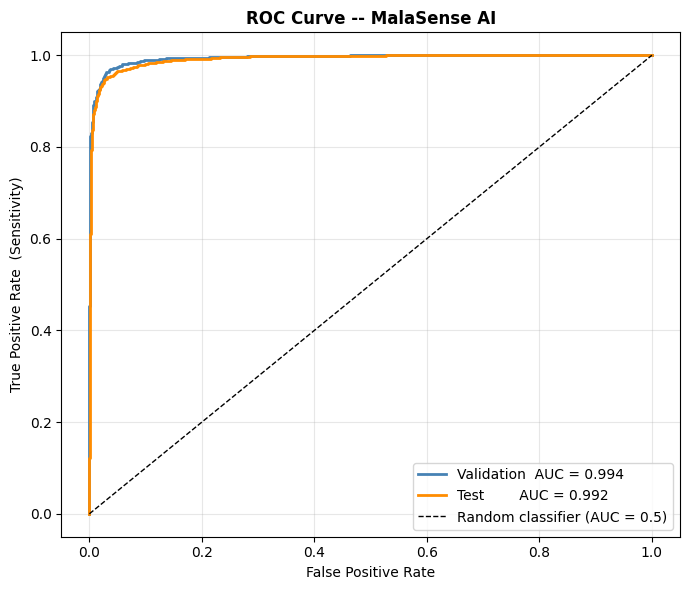

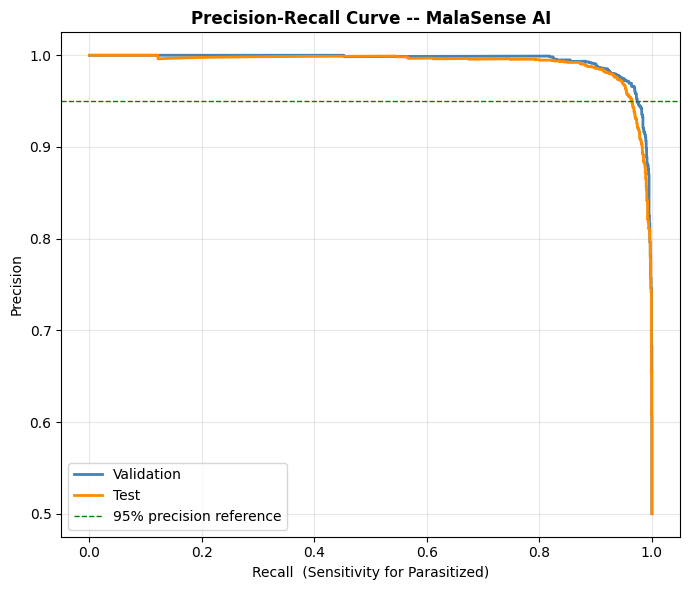

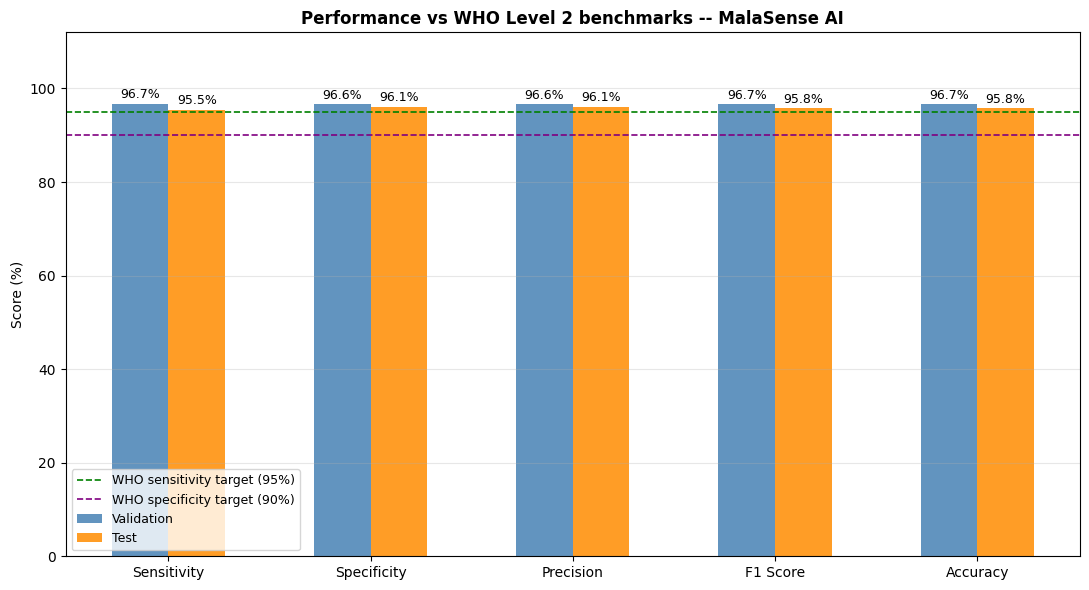

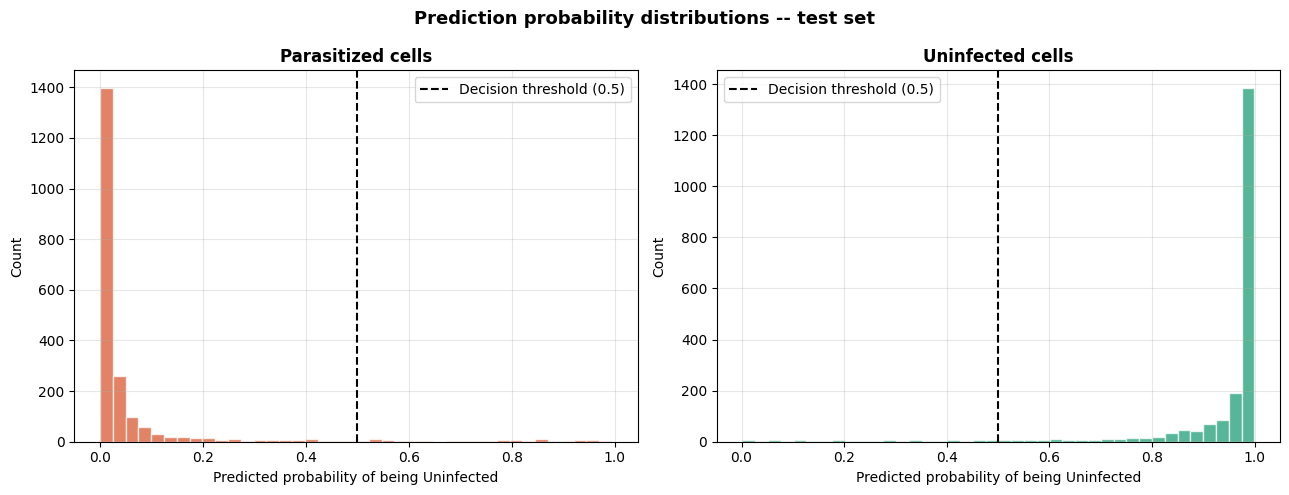


FINAL SUMMARY -- MalaSense AI
Metric                                Validation         Test
--------------------------------------------------------------
Accuracy                                  96.67%       95.79%
Sensitivity (Parasitized recall)          96.75%       95.45%
Specificity                               96.60%       96.13%
Precision                                 96.61%       96.10%
F1 Score                                  96.68%       95.78%
ROC AUC                                   0.994        0.992
--------------------------------------------------------------
WHO sensitivity target                     >=95%        >=95%
WHO specificity target                     >=90%        >=90%
Evaluation complete!


In [10]:
# ── Smoothing helper for training curves ───────────────────────────────────────
def smooth(values, weight=0.6):
    # Exponential moving average -- reduces spike noise in validation curves
    smoothed, last = [], values[0]
    for v in values:
        last = last * weight + v * (1 - weight)
        smoothed.append(last)
    return smoothed

# ── Run predictions on BOTH validation and test sets ──────────────────────────
# Validation set: the set monitored during training
# Test set      : completely unseen until now -- the honest performance estimate
print("Running predictions on validation and test sets...")

val_probs  = model.predict(X_val,  batch_size=32, verbose=1).flatten()
test_probs = model.predict(X_test, batch_size=32, verbose=1).flatten()

# Convert sigmoid probabilities to binary class labels at threshold 0.5
# Below 0.5 = Parasitized (class 0), Above 0.5 = Uninfected (class 1)
val_preds  = (val_probs  > 0.5).astype(int)
test_preds = (test_probs > 0.5).astype(int)

y_val_int  = y_val.astype(int)
y_test_int = y_test.astype(int)

print(f"Validation -- unique prediction counts : {np.unique(val_preds,  return_counts=True)}")
print(f"Test       -- unique prediction counts : {np.unique(test_preds, return_counts=True)}")

# ── Classification reports ─────────────────────────────────────────────────────
print()
print("=" * 60)
print("VALIDATION SET -- Classification Report")
print("=" * 60)
print(classification_report(
    y_val_int, val_preds,
    target_names=['Parasitized', 'Uninfected']
))

print("=" * 60)
print("TEST SET -- Classification Report")
print("=" * 60)
print(classification_report(
    y_test_int, test_preds,
    target_names=['Parasitized', 'Uninfected']
))

# ── Clinical metrics helper ────────────────────────────────────────────────────
def clinical_metrics(y_true, y_pred, label=""):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm.ravel()

    # Sensitivity: of all infected cells, how many did we correctly catch?
    # WHO Level 2 target >= 95%
    sensitivity = TN / (TN + FP) if (TN + FP) > 0 else 0

    # Specificity: of all healthy cells, how many did we correctly clear?
    # WHO Level 2 target >= 90%
    specificity = TP / (TP + FN) if (TP + FN) > 0 else 0

    # Precision: of all cells we flagged as infected, how many truly were?
    precision   = TN / (TN + FN) if (TN + FN) > 0 else 0

    # F1 score: harmonic mean of precision and sensitivity
    f1 = (2 * precision * sensitivity / (precision + sensitivity)
          if (precision + sensitivity) > 0 else 0)

    # Overall accuracy
    accuracy = (TN + TP) / (TN + FP + FN + TP)

    print(f"{label} Clinical Performance Metrics")
    print("-" * 55)
    print(f"  Accuracy                         : {accuracy*100:.2f}%")
    print(f"  Sensitivity (Parasitized recall) : {sensitivity*100:.2f}%"
          f"   (WHO target >= 95%)")
    print(f"  Specificity                      : {specificity*100:.2f}%"
          f"   (WHO target >= 90%)")
    print(f"  Precision                        : {precision*100:.2f}%")
    print(f"  F1 Score                         : {f1*100:.2f}%")
    print(f"  Confusion values: TN={TN}  FP={FP}  FN={FN}  TP={TP}")
    print()
    return cm, sensitivity, specificity, precision, f1, accuracy

print("=" * 60)
cm_val,  sv,  spv, pv,  f1v, accv = clinical_metrics(y_val_int,  val_preds,  "VALIDATION --")
cm_test, st,  spt, pt,  f1t, acct = clinical_metrics(y_test_int, test_preds, "TEST       --")

# ════════════════════════════════════════════════════════════════
# FIGURE 1 -- Confusion Matrices (validation and test side by side)
# ════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Confusion Matrices -- MalaSense AI", fontsize=14, fontweight='bold')

for ax, cm, title in zip(
    axes,
    [cm_val, cm_test],
    ["Validation set", "Test set (unseen)"]
):
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Parasitized', 'Uninfected'],
        yticklabels=['Parasitized', 'Uninfected'],
        linewidths=0.5
    )
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Actual label')
    ax.set_xlabel('Predicted label')

plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 2 -- Training curves (accuracy and loss over epochs)
# ════════════════════════════════════════════════════════════════
train_acc  = history.history['accuracy']
val_acc    = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss   = history.history['val_loss']
epochs_ran = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training history -- MalaSense AI", fontsize=14, fontweight='bold')

# Accuracy curve
axes[0].plot(epochs_ran, train_acc,
             color='steelblue', linewidth=2, label='Training accuracy')
axes[0].plot(epochs_ran, val_acc,
             color='darkorange', linewidth=1, alpha=0.35, label='Validation (raw)')
axes[0].plot(epochs_ran, smooth(val_acc),
             color='darkorange', linewidth=2, label='Validation (smoothed)')
axes[0].axhline(0.95, color='green',  linestyle='--', linewidth=1,
                label='WHO sensitivity target (95%)')
axes[0].axhline(0.90, color='purple', linestyle='--', linewidth=1,
                label='WHO specificity target (90%)')
axes[0].set_title('Accuracy over epochs', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0.4, 1.05])

# Loss curve
axes[1].plot(epochs_ran, train_loss,
             color='steelblue', linewidth=2, label='Training loss')
axes[1].plot(epochs_ran, val_loss,
             color='darkorange', linewidth=1, alpha=0.35, label='Validation (raw)')
axes[1].plot(epochs_ran, smooth(val_loss),
             color='darkorange', linewidth=2, label='Validation (smoothed)')
axes[1].set_title('Loss over epochs', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 3 -- ROC Curves (validation and test on same axes)
# ════════════════════════════════════════════════════════════════
# ROC curve plots sensitivity vs false positive rate at every threshold.
# AUC of 1.0 = perfect classifier. AUC of 0.5 = random guessing.
# pos_label=0 because Parasitized is class 0 and is the positive case clinically.

fpr_val,  tpr_val,  _ = roc_curve(y_val_int,  1 - val_probs,  pos_label=0)
fpr_test, tpr_test, _ = roc_curve(y_test_int, 1 - test_probs, pos_label=0)
auc_val  = auc(fpr_val,  tpr_val)
auc_test = auc(fpr_test, tpr_test)

plt.figure(figsize=(7, 6))
plt.plot(fpr_val,  tpr_val,  color='steelblue',  linewidth=2,
         label=f'Validation  AUC = {auc_val:.3f}')
plt.plot(fpr_test, tpr_test, color='darkorange', linewidth=2,
         label=f'Test        AUC = {auc_test:.3f}')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate  (Sensitivity)')
plt.title('ROC Curve -- MalaSense AI', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 4 -- Precision-Recall Curves
# ════════════════════════════════════════════════════════════════
# Precision-Recall is more informative than ROC for clinical tasks where
# missing an infection (false negative) has serious consequences.
# We want high recall (catch all infected cells) even at some cost to precision.

prec_val,  rec_val,  _ = precision_recall_curve(
    y_val_int,  1 - val_probs,  pos_label=0)
prec_test, rec_test, _ = precision_recall_curve(
    y_test_int, 1 - test_probs, pos_label=0)

plt.figure(figsize=(7, 6))
plt.plot(rec_val,  prec_val,  color='steelblue',  linewidth=2, label='Validation')
plt.plot(rec_test, prec_test, color='darkorange', linewidth=2, label='Test')
plt.axhline(0.95, color='green', linestyle='--', linewidth=1,
            label='95% precision reference')
plt.xlabel('Recall  (Sensitivity for Parasitized)')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve -- MalaSense AI', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 5 -- WHO Level 2 target comparison bar chart
# ════════════════════════════════════════════════════════════════
metrics_labels = ['Sensitivity', 'Specificity', 'Precision', 'F1 Score', 'Accuracy']
val_scores     = [sv,  spv, pv,  f1v, accv]
test_scores    = [st,  spt, pt,  f1t, acct]

x     = np.arange(len(metrics_labels))
width = 0.28

fig, ax = plt.subplots(figsize=(11, 6))
bars_val  = ax.bar(x - width/2, [s*100 for s in val_scores],
                   width, label='Validation', color='steelblue',  alpha=0.85)
bars_test = ax.bar(x + width/2, [s*100 for s in test_scores],
                   width, label='Test',       color='darkorange', alpha=0.85)

# WHO benchmark reference lines
ax.axhline(95, color='green',  linestyle='--', linewidth=1.2,
           label='WHO sensitivity target (95%)')
ax.axhline(90, color='purple', linestyle='--', linewidth=1.2,
           label='WHO specificity target (90%)')

# Value labels on each bar
for bar in list(bars_val) + list(bars_test):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
            f'{h:.1f}%', ha='center', va='bottom', fontsize=9)

ax.set_ylabel('Score (%)')
ax.set_title('Performance vs WHO Level 2 benchmarks -- MalaSense AI',
             fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_labels)
ax.set_ylim([0, 112])
ax.legend(fontsize=9)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 6 -- Prediction probability distributions (test set)
# ════════════════════════════════════════════════════════════════
# A well-calibrated model pushes predictions toward 0 (parasitized) and 1
# (uninfected), not clustering near 0.5 (uncertain).
# Good separation between the two histograms = confident, correct predictions.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Prediction probability distributions -- test set",
             fontsize=13, fontweight='bold')

para_mask  = y_test_int == 0   # actually parasitized cells
uninf_mask = y_test_int == 1   # actually uninfected cells

# Parasitized cells: model should predict LOW probability (close to 0)
axes[0].hist(test_probs[para_mask],  bins=40,
             color='#D85A30', alpha=0.75, edgecolor='white')
axes[0].axvline(0.5, color='black', linestyle='--',
                linewidth=1.5, label='Decision threshold (0.5)')
axes[0].set_title('Parasitized cells', fontweight='bold')
axes[0].set_xlabel('Predicted probability of being Uninfected')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Uninfected cells: model should predict HIGH probability (close to 1)
axes[1].hist(test_probs[uninf_mask], bins=40,
             color='#1D9E75', alpha=0.75, edgecolor='white')
axes[1].axvline(0.5, color='black', linestyle='--',
                linewidth=1.5, label='Decision threshold (0.5)')
axes[1].set_title('Uninfected cells', fontweight='bold')
axes[1].set_xlabel('Predicted probability of being Uninfected')
axes[1].set_ylabel('Count')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── Final summary table ────────────────────────────────────────────────────────
print()
print("=" * 62)
print("FINAL SUMMARY -- MalaSense AI")
print("=" * 62)
print(f"{'Metric':<35} {'Validation':>12} {'Test':>12}")
print("-" * 62)
print(f"{'Accuracy':<35} {accv*100:>11.2f}% {acct*100:>11.2f}%")
print(f"{'Sensitivity (Parasitized recall)':<35} {sv*100:>11.2f}% {st*100:>11.2f}%")
print(f"{'Specificity':<35} {spv*100:>11.2f}% {spt*100:>11.2f}%")
print(f"{'Precision':<35} {pv*100:>11.2f}% {pt*100:>11.2f}%")
print(f"{'F1 Score':<35} {f1v*100:>11.2f}% {f1t*100:>11.2f}%")
print(f"{'ROC AUC':<35} {auc_val:>11.3f}  {auc_test:>11.3f}")
print("-" * 62)
print(f"{'WHO sensitivity target':<35} {'>=95%':>12} {'>=95%':>12}")
print(f"{'WHO specificity target':<35} {'>=90%':>12} {'>=90%':>12}")
print("=" * 62)
print("Evaluation complete!")

# ── Smoothing helper for training curves ───────────────────────────────────────
def smooth(values, weight=0.6):
    # Exponential moving average -- reduces spike noise in validation curves
    smoothed, last = [], values[0]
    for v in values:
        last = last * weight + v * (1 - weight)
        smoothed.append(last)
    return smoothed

# ── Run predictions on BOTH validation and test sets ──────────────────────────
# Validation set: the set monitored during training
# Test set      : completely unseen until now -- the honest performance estimate
print("Running predictions on validation and test sets...")

val_probs  = model.predict(X_val,  batch_size=32, verbose=1).flatten()
test_probs = model.predict(X_test, batch_size=32, verbose=1).flatten()

# Convert sigmoid probabilities to binary class labels at threshold 0.5
# Below 0.5 = Parasitized (class 0), Above 0.5 = Uninfected (class 1)
val_preds  = (val_probs  > 0.5).astype(int)
test_preds = (test_probs > 0.5).astype(int)

y_val_int  = y_val.astype(int)
y_test_int = y_test.astype(int)

print(f"Validation -- unique prediction counts : {np.unique(val_preds,  return_counts=True)}")
print(f"Test       -- unique prediction counts : {np.unique(test_preds, return_counts=True)}")

# ── Classification reports ─────────────────────────────────────────────────────
print()
print("=" * 60)
print("VALIDATION SET -- Classification Report")
print("=" * 60)
print(classification_report(
    y_val_int, val_preds,
    target_names=['Parasitized', 'Uninfected']
))

print("=" * 60)
print("TEST SET -- Classification Report")
print("=" * 60)
print(classification_report(
    y_test_int, test_preds,
    target_names=['Parasitized', 'Uninfected']
))

# ── Clinical metrics helper ────────────────────────────────────────────────────
def clinical_metrics(y_true, y_pred, label=""):
    cm = confusion_matrix(y_true, y_pred)
    TN, FP, FN, TP = cm.ravel()

    # Sensitivity: of all infected cells, how many did we correctly catch?
    # WHO Level 2 target >= 95%
    sensitivity = TN / (TN + FP) if (TN + FP) > 0 else 0

    # Specificity: of all healthy cells, how many did we correctly clear?
    # WHO Level 2 target >= 90%
    specificity = TP / (TP + FN) if (TP + FN) > 0 else 0

    # Precision: of all cells we flagged as infected, how many truly were?
    precision   = TN / (TN + FN) if (TN + FN) > 0 else 0

    # F1 score: harmonic mean of precision and sensitivity
    f1 = (2 * precision * sensitivity / (precision + sensitivity)
          if (precision + sensitivity) > 0 else 0)

    # Overall accuracy
    accuracy = (TN + TP) / (TN + FP + FN + TP)

    print(f"{label} Clinical Performance Metrics")
    print("-" * 55)
    print(f"  Accuracy                         : {accuracy*100:.2f}%")
    print(f"  Sensitivity (Parasitized recall) : {sensitivity*100:.2f}%"
          f"   (WHO target >= 95%)")
    print(f"  Specificity                      : {specificity*100:.2f}%"
          f"   (WHO target >= 90%)")
    print(f"  Precision                        : {precision*100:.2f}%")
    print(f"  F1 Score                         : {f1*100:.2f}%")
    print(f"  Confusion values: TN={TN}  FP={FP}  FN={FN}  TP={TP}")
    print()
    return cm, sensitivity, specificity, precision, f1, accuracy

print("=" * 60)
cm_val,  sv,  spv, pv,  f1v, accv = clinical_metrics(y_val_int,  val_preds,  "VALIDATION --")
cm_test, st,  spt, pt,  f1t, acct = clinical_metrics(y_test_int, test_preds, "TEST       --")

# ════════════════════════════════════════════════════════════════
# FIGURE 1 -- Confusion Matrices (validation and test side by side)
# ════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Confusion Matrices -- MalaSense AI", fontsize=14, fontweight='bold')

for ax, cm, title in zip(
    axes,
    [cm_val, cm_test],
    ["Validation set", "Test set (unseen)"]
):
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Parasitized', 'Uninfected'],
        yticklabels=['Parasitized', 'Uninfected'],
        linewidths=0.5
    )
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Actual label')
    ax.set_xlabel('Predicted label')

plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 2 -- Training curves (accuracy and loss over epochs)
# ════════════════════════════════════════════════════════════════
train_acc  = history.history['accuracy']
val_acc    = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss   = history.history['val_loss']
epochs_ran = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training history -- MalaSense AI", fontsize=14, fontweight='bold')

# Accuracy curve
axes[0].plot(epochs_ran, train_acc,
             color='steelblue', linewidth=2, label='Training accuracy')
axes[0].plot(epochs_ran, val_acc,
             color='darkorange', linewidth=1, alpha=0.35, label='Validation (raw)')
axes[0].plot(epochs_ran, smooth(val_acc),
             color='darkorange', linewidth=2, label='Validation (smoothed)')
axes[0].axhline(0.95, color='green',  linestyle='--', linewidth=1,
                label='WHO sensitivity target (95%)')
axes[0].axhline(0.90, color='purple', linestyle='--', linewidth=1,
                label='WHO specificity target (90%)')
axes[0].set_title('Accuracy over epochs', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0.4, 1.05])

# Loss curve
axes[1].plot(epochs_ran, train_loss,
             color='steelblue', linewidth=2, label='Training loss')
axes[1].plot(epochs_ran, val_loss,
             color='darkorange', linewidth=1, alpha=0.35, label='Validation (raw)')
axes[1].plot(epochs_ran, smooth(val_loss),
             color='darkorange', linewidth=2, label='Validation (smoothed)')
axes[1].set_title('Loss over epochs', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 3 -- ROC Curves (validation and test on same axes)
# ════════════════════════════════════════════════════════════════
# ROC curve plots sensitivity vs false positive rate at every threshold.
# AUC of 1.0 = perfect classifier. AUC of 0.5 = random guessing.
# pos_label=0 because Parasitized is class 0 and is the positive case clinically.

fpr_val,  tpr_val,  _ = roc_curve(y_val_int,  1 - val_probs,  pos_label=0)
fpr_test, tpr_test, _ = roc_curve(y_test_int, 1 - test_probs, pos_label=0)
auc_val  = auc(fpr_val,  tpr_val)
auc_test = auc(fpr_test, tpr_test)

plt.figure(figsize=(7, 6))
plt.plot(fpr_val,  tpr_val,  color='steelblue',  linewidth=2,
         label=f'Validation  AUC = {auc_val:.3f}')
plt.plot(fpr_test, tpr_test, color='darkorange', linewidth=2,
         label=f'Test        AUC = {auc_test:.3f}')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random classifier (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate  (Sensitivity)')
plt.title('ROC Curve -- MalaSense AI', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 4 -- Precision-Recall Curves
# ════════════════════════════════════════════════════════════════
# Precision-Recall is more informative than ROC for clinical tasks where
# missing an infection (false negative) has serious consequences.
# We want high recall (catch all infected cells) even at some cost to precision.

prec_val,  rec_val,  _ = precision_recall_curve(
    y_val_int,  1 - val_probs,  pos_label=0)
prec_test, rec_test, _ = precision_recall_curve(
    y_test_int, 1 - test_probs, pos_label=0)

plt.figure(figsize=(7, 6))
plt.plot(rec_val,  prec_val,  color='steelblue',  linewidth=2, label='Validation')
plt.plot(rec_test, prec_test, color='darkorange', linewidth=2, label='Test')
plt.axhline(0.95, color='green', linestyle='--', linewidth=1,
            label='95% precision reference')
plt.xlabel('Recall  (Sensitivity for Parasitized)')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve -- MalaSense AI', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 5 -- WHO Level 2 target comparison bar chart
# ════════════════════════════════════════════════════════════════
metrics_labels = ['Sensitivity', 'Specificity', 'Precision', 'F1 Score', 'Accuracy']
val_scores     = [sv,  spv, pv,  f1v, accv]
test_scores    = [st,  spt, pt,  f1t, acct]

x     = np.arange(len(metrics_labels))
width = 0.28

fig, ax = plt.subplots(figsize=(11, 6))
bars_val  = ax.bar(x - width/2, [s*100 for s in val_scores],
                   width, label='Validation', color='steelblue',  alpha=0.85)
bars_test = ax.bar(x + width/2, [s*100 for s in test_scores],
                   width, label='Test',       color='darkorange', alpha=0.85)

# WHO benchmark reference lines
ax.axhline(95, color='green',  linestyle='--', linewidth=1.2,
           label='WHO sensitivity target (95%)')
ax.axhline(90, color='purple', linestyle='--', linewidth=1.2,
           label='WHO specificity target (90%)')

# Value labels on each bar
for bar in list(bars_val) + list(bars_test):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.5,
            f'{h:.1f}%', ha='center', va='bottom', fontsize=9)

ax.set_ylabel('Score (%)')
ax.set_title('Performance vs WHO Level 2 benchmarks -- MalaSense AI',
             fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_labels)
ax.set_ylim([0, 112])
ax.legend(fontsize=9)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════════
# FIGURE 6 -- Prediction probability distributions (test set)
# ════════════════════════════════════════════════════════════════
# A well-calibrated model pushes predictions toward 0 (parasitized) and 1
# (uninfected), not clustering near 0.5 (uncertain).
# Good separation between the two histograms = confident, correct predictions.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Prediction probability distributions -- test set",
             fontsize=13, fontweight='bold')

para_mask  = y_test_int == 0   # actually parasitized cells
uninf_mask = y_test_int == 1   # actually uninfected cells

# Parasitized cells: model should predict LOW probability (close to 0)
axes[0].hist(test_probs[para_mask],  bins=40,
             color='#D85A30', alpha=0.75, edgecolor='white')
axes[0].axvline(0.5, color='black', linestyle='--',
                linewidth=1.5, label='Decision threshold (0.5)')
axes[0].set_title('Parasitized cells', fontweight='bold')
axes[0].set_xlabel('Predicted probability of being Uninfected')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Uninfected cells: model should predict HIGH probability (close to 1)
axes[1].hist(test_probs[uninf_mask], bins=40,
             color='#1D9E75', alpha=0.75, edgecolor='white')
axes[1].axvline(0.5, color='black', linestyle='--',
                linewidth=1.5, label='Decision threshold (0.5)')
axes[1].set_title('Uninfected cells', fontweight='bold')
axes[1].set_xlabel('Predicted probability of being Uninfected')
axes[1].set_ylabel('Count')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── Final summary table ────────────────────────────────────────────────────────
print()
print("=" * 62)
print("FINAL SUMMARY -- MalaSense AI")
print("=" * 62)
print(f"{'Metric':<35} {'Validation':>12} {'Test':>12}")
print("-" * 62)
print(f"{'Accuracy':<35} {accv*100:>11.2f}% {acct*100:>11.2f}%")
print(f"{'Sensitivity (Parasitized recall)':<35} {sv*100:>11.2f}% {st*100:>11.2f}%")
print(f"{'Specificity':<35} {spv*100:>11.2f}% {spt*100:>11.2f}%")
print(f"{'Precision':<35} {pv*100:>11.2f}% {pt*100:>11.2f}%")
print(f"{'F1 Score':<35} {f1v*100:>11.2f}% {f1t*100:>11.2f}%")
print(f"{'ROC AUC':<35} {auc_val:>11.3f}  {auc_test:>11.3f}")
print("-" * 62)
print(f"{'WHO sensitivity target':<35} {'>=95%':>12} {'>=95%':>12}")
print(f"{'WHO specificity target':<35} {'>=90%':>12} {'>=90%':>12}")
print("=" * 62)
print("Evaluation complete!")